In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch

from rl4co.envs import CVRPEnv
from rl4co.models.zoo.decomposition import DECOMP, KmeansPol, BaryCenterDecomp, Delegate
from rl4co.models.zoo.am import AttentionModelPolicy

/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/andrewtao/opt/anaconda3/envs/rl4co/lib/python3.11/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


In [3]:
torch.manual_seed(42)

env = CVRPEnv(generator_params={'num_loc': 40})
# model = DECOMP(env,
#                 baseline='rollout',
#                 train_data_size=1_000,
#                 val_data_size=100)

In [4]:
decomp_pol = BaryCenterDecomp(4)
naive_pol = AttentionModelPolicy(env_name=env.name)

In [49]:
td = env.reset(batch_size=[4])
out = naive_pol(td, env, return_actions=True)

In [33]:
def render_all(td, out, env):
    for td, actions in zip(td, out['actions'].cpu()):
        env.render(td, actions)

In [131]:
out["actions"].shape

torch.Size([16, 66])

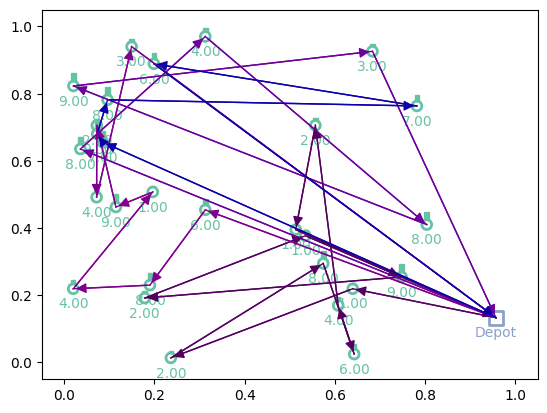

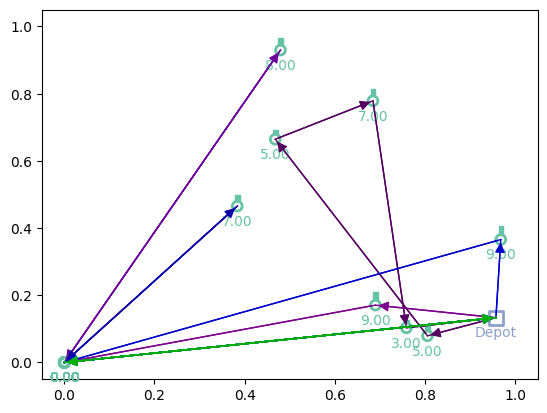

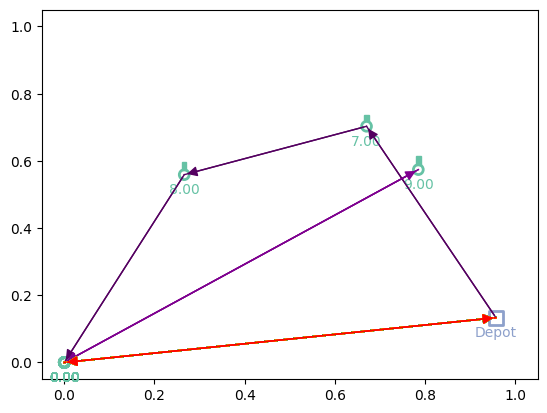

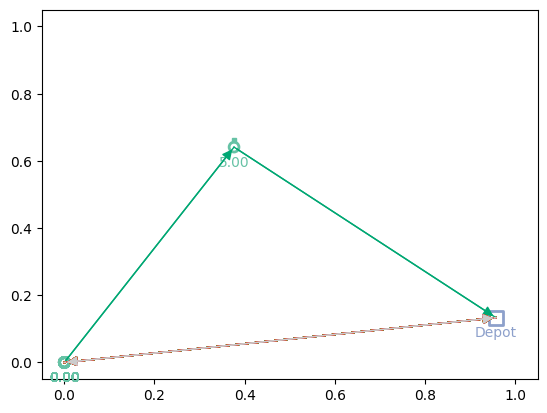

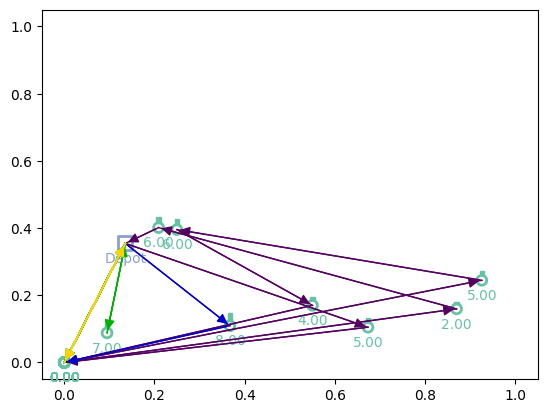

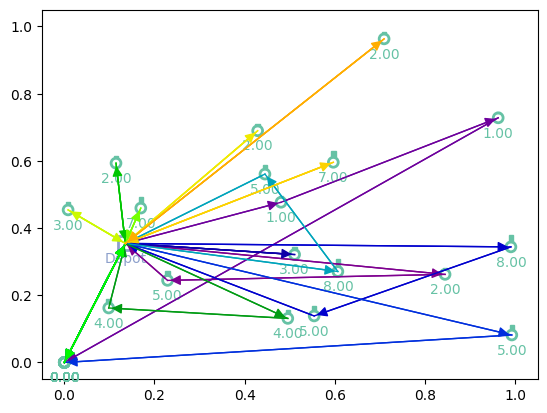

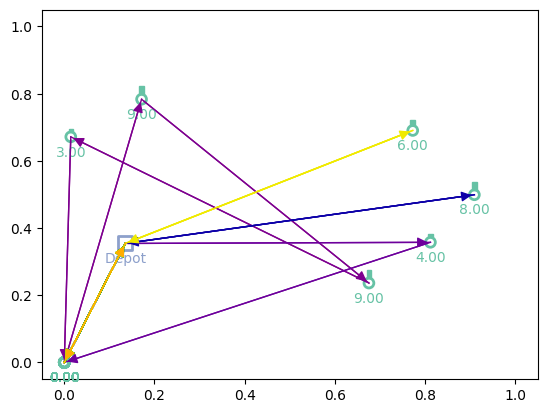

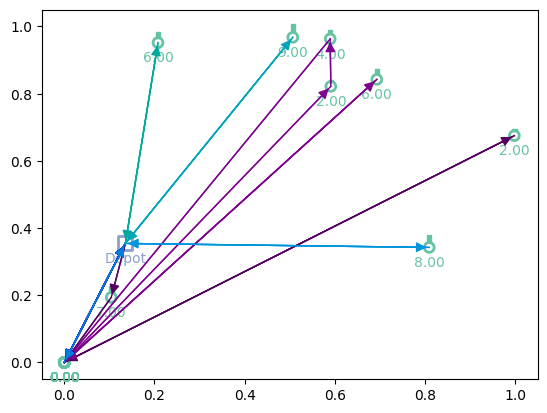

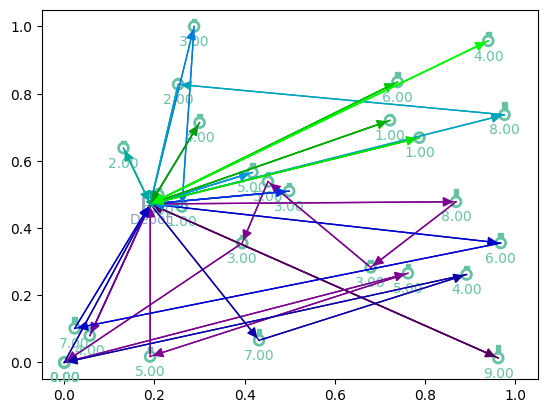

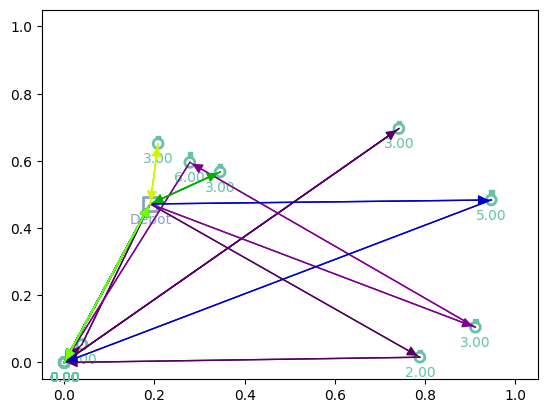

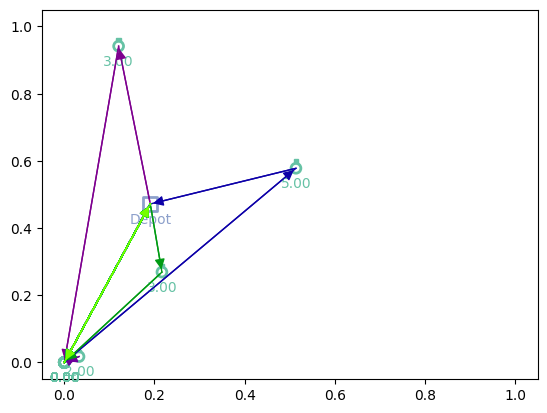

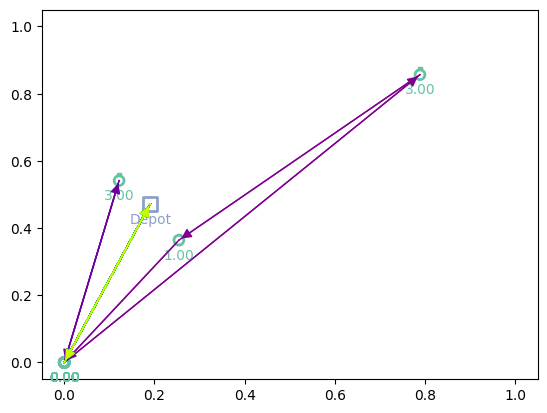

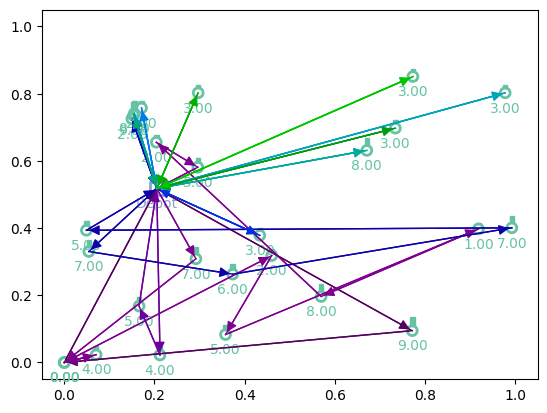

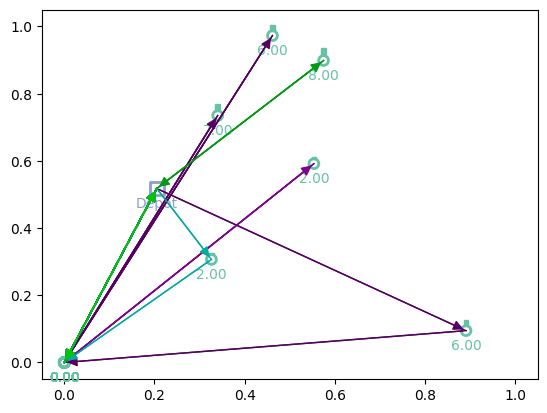

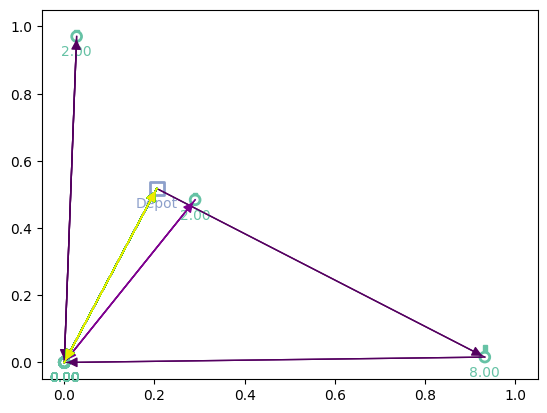

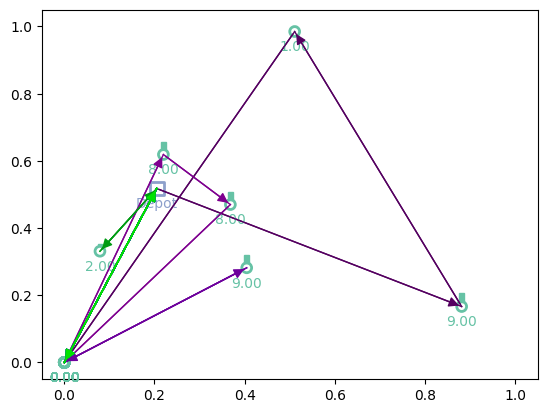

In [34]:
render_all(td_reset, out, env)

In [50]:
td_new = decomp_pol.decompose(td, env, out)

In [51]:
td_new

TensorDict(
    fields={
        capacity: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        demand: Tensor(shape=torch.Size([16, 32]), device=cpu, dtype=torch.float32, is_shared=False),
        depot: Tensor(shape=torch.Size([16, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        locs: Tensor(shape=torch.Size([16, 32, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        problem_mask: Tensor(shape=torch.Size([16, 32]), device=cpu, dtype=torch.bool, is_shared=False)},
    batch_size=torch.Size([16]),
    device=None,
    is_shared=False)

In [52]:
td_reset = env.reset(td_new)

In [53]:
td_reset

TensorDict(
    fields={
        action_mask: Tensor(shape=torch.Size([16, 33]), device=cpu, dtype=torch.bool, is_shared=False),
        capacity: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        current_node: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.int64, is_shared=False),
        demand: Tensor(shape=torch.Size([16, 32]), device=cpu, dtype=torch.float32, is_shared=False),
        depot: Tensor(shape=torch.Size([16, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        done: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        locs: Tensor(shape=torch.Size([16, 33, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        problem_mask: Tensor(shape=torch.Size([16, 32]), device=cpu, dtype=torch.bool, is_shared=False),
        terminated: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.bool, is_shared=False),
        used_capacity: Tensor(shape=torch.Size([16, 1])

In [54]:
out = naive_pol(td_reset, env, return_actions=True)

In [55]:
out

{'reward': tensor([-10.1075, -22.8728, -19.6339, -13.0310, -41.3208, -18.0338, -19.0792,
         -30.8022, -23.1615, -64.2543, -60.5311, -60.1485, -17.8739, -22.4029,
         -20.1805, -18.6560]),
 'log_likelihood': tensor([-90.5150, -73.6928, -86.8864, -85.8552, -92.3884, -60.8925, -87.4940,
         -95.3762, -72.0570, -82.9390, -88.9641, -95.9022, -92.9960, -84.4225,
         -97.4725, -84.1438], grad_fn=<SumBackward1>),
 'actions': tensor([[ 7,  8,  5,  1,  3,  2,  0, 29, 23, 25, 31,  0, 20, 13, 30,  0,  4,  0,
          22, 27,  0, 16,  9,  0, 28, 14,  0, 11,  0, 26,  0,  6,  0, 17,  0, 18,
           0, 19,  0, 32,  0, 24,  0, 12,  0, 10,  0, 15,  0, 21,  0,  0,  0,  0,
           0,  0,  0],
         [30, 10, 27, 26, 20, 28, 15, 32, 29, 23,  5,  2, 31, 14,  1,  0, 25, 21,
          16, 18, 22, 17,  0,  4,  9,  0,  8, 12,  0,  3,  0, 11,  0, 13,  0,  6,
           0, 24,  0, 19,  0,  7,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
           0,  0,  0],
         [ 6, 14,  7,

In [39]:
from rl4co.utils.ops import batchify, unbatchify
from einops import rearrange

In [56]:
td_reset

TensorDict(
    fields={
        action: Tensor(shape=torch.Size([16]), device=cpu, dtype=torch.int64, is_shared=False),
        action_mask: Tensor(shape=torch.Size([16, 33]), device=cpu, dtype=torch.bool, is_shared=False),
        capacity: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.float32, is_shared=False),
        current_node: Tensor(shape=torch.Size([16, 1]), device=cpu, dtype=torch.int64, is_shared=False),
        demand: Tensor(shape=torch.Size([16, 32]), device=cpu, dtype=torch.float32, is_shared=False),
        depot: Tensor(shape=torch.Size([16, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        done: Tensor(shape=torch.Size([16]), device=cpu, dtype=torch.bool, is_shared=False),
        locs: Tensor(shape=torch.Size([16, 33, 2]), device=cpu, dtype=torch.float32, is_shared=False),
        problem_mask: Tensor(shape=torch.Size([16, 32]), device=cpu, dtype=torch.bool, is_shared=False),
        reward: Tensor(shape=torch.Size([16]), device=cpu, dtype

In [61]:
tmp.shape

torch.Size([4, 132, 2])

In [63]:
k = 4
tmp = td_reset["locs"][:, 1:].reshape(td_reset.shape[0] // k, k * (td_reset["locs"].shape[1] - 1), 2)

In [66]:
tmp = td_reset["locs"][:, 1:]

In [110]:
k = 4
tmp = out["actions"]
bs = out["actions"].shape[0] // k
actions = torch.zeros(size=(bs, bs * out["actions"].shape[1]))
for i in range(len(out["actions"]) // 4):
    row = torch.tensor([])
    for j in range(4):
        row = torch.cat((row, tmp[4 * i + j, :endIndex(tmp[4 * i + j])]))
    actions[i, :len(row)] = row

In [97]:
def endIndex(row):
    i = len(row) - 1
    while i > 0 and row[i] == 0:
        i -= 1
    return i + 1

In [111]:
actions

tensor([[ 7.,  8.,  5.,  1.,  3.,  2.,  0., 29., 23., 25., 31.,  0., 20., 13.,
         30.,  0.,  4.,  0., 22., 27.,  0., 16.,  9.,  0., 28., 14.,  0., 11.,
          0., 26.,  0.,  6.,  0., 17.,  0., 18.,  0., 19.,  0., 32.,  0., 24.,
          0., 12.,  0., 10.,  0., 15.,  0., 21., 30., 10., 27., 26., 20., 28.,
         15., 32., 29., 23.,  5.,  2., 31., 14.,  1.,  0., 25., 21., 16., 18.,
         22., 17.,  0.,  4.,  9.,  0.,  8., 12.,  0.,  3.,  0., 11.,  0., 13.,
          0.,  6.,  0., 24.,  0., 19.,  0.,  7.,  6., 14.,  7.,  9., 29.,  1.,
         16.,  0.,  5., 20.,  4., 30.,  2., 19.,  0., 21.,  0., 23.,  0., 25.,
          0., 11.,  0.,  3., 32.,  0., 24.,  0., 18.,  0., 13.,  0., 27.,  0.,
          8.,  0., 15.,  0., 12.,  0., 26.,  0., 22.,  0., 31.,  0., 10.,  0.,
         28.,  0., 17., 30., 31.,  5.,  3., 14., 24.,  9., 29., 23., 26.,  4.,
         13.,  0., 18.,  0.,  8.,  2., 32.,  0., 20.,  0., 22.,  0., 19.,  0.,
          7.,  0., 11.,  0., 10.,  0.,  1., 25.,  0.

In [71]:
assert tmp.shape == td_reset["problem_mask"].shape

AssertionError: 

In [79]:
tmp2 = tmp[td_reset["problem_mask"], :]

In [82]:
tmp2.reshape(-1, 40, 2).shape

torch.Size([4, 40, 2])

In [85]:
out["actions"].shape

torch.Size([16, 57])

In [87]:
out["actions"][1]

tensor([30, 10, 27, 26, 20, 28, 15, 32, 29, 23,  5,  2, 31, 14,  1,  0, 25, 21,
        16, 18, 22, 17,  0,  4,  9,  0,  8, 12,  0,  3,  0, 11,  0, 13,  0,  6,
         0, 24,  0, 19,  0,  7,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])